<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/> 

# Regression and Classification
---
<small>© COPYRIGHT 2026 DECODED LIMITED. ALL RIGHTS RESERVED. Web: https://decoded.com/ </small>

### Summary
In this chapter we will dive into the powerful world of classification, a fundamental task in the field of machine learning and data analysis. Through a combination of theory, hands-on exercises, and real-world examples, we will explore various classification algorithms, discuss evaluation metrics, and uncover strategies for feature selection and model optimization. 



### Learning Objectives
- Understand the concept of classification and its importance in machine learning and data analysis
- Identify different types of classification problems, such as binary, multi-class, and multi-label classification
- Understand common classification algorithms, including decision trees, logistic regression, and k-nearest neighbors (k-NN)
- Compare and contrast the strengths and limitations of various classification algorithms, enabling informed algorithm selection for different datasets
- Evaluate the performance of classification models using appropriate evaluation metrics, such as accuracy, precision, recall, F1 score, and ROC curves
- Implement classification algorithms in Python using popular libraries such as scikit-learn
- Gain hands-on experience in preprocessing and feature engineering techniques to enhance classification model performance
- Apply best practices for model training, testing, and validation, including strategies for cross-validation and hyperparameter tuning to optimize classification models


---

### Overview


[**What is classification?**](#what_is_classification)
- What is classification?
- How is classification different than regression? 
- What are the different types of classification problems? 
- What are example uses of classification? 
- *Challenge*: Discuss applications of classification

[**What is a classification model?**](#classification_models)
- What are examples of different classification algorithms? 
- What is logistic regression algorithm? 
- What is the Decision Tree algorithm?
- *Challenge*: Compare applications of linear regression and logistic regression 

[**How do I interpret classification models?**](#interpreting_classification_models)
- How do I interpret a logistic regression model?
- How do I interpret a Decision Tree model?
- *Challenge*: Create a decision tree by hand



[**How to ML algorithms find classification models?**](#ml_algorithms)
- How does the logistic regression algorithm find a logistic regression model? 
- How do you implement logistic regression in Python?
- *Demo*: Use `LogisticRegression()` from `sklearn` to train a model
- How does the Decision Tree algorithm find a Decision Tree model?
- How do you implement Decision Trees in Python?
- *Demo*: Use `DecisionTreeClassifier()` from `sklearn` to train a model

[**How do I choose between classification models?**](#model_selection)
- What is model selection?
- What is a validation set?  
- How do you use grid search to tune hyperparameters?
- *Challenge*: Use `GridSearchCV` from `sklearn` to perform model selection

[**How do I evaluate classification models?**](#model_evaluation)
- Why are models evaluated on a test set?
- What is a confusion matrix? 
- *Challenge*: Use `confusion_matrix` from `sklearn` to display classification model outcomes 

### Introductions

#### Purpose: What is the aim of the content?

The purpose of this introductory workshop on classification is to equip learners with the knowledge and skills necessary to effectively tackle classification problems in machine learning and data analysis. Classification is a fundamental task that involves categorizing data into distinct classes or categories based on their features. Understanding how to classify data accurately is crucial in various domains, including finance, healthcare, marketing, and many others. This workshop aims to provide a comprehensive overview of classification concepts, algorithms, evaluation techniques, and implementation in Python. 


#### Objectives: What will I learn?
- Understand the concept of classification and its importance in machine learning and data analysis
- Identify different types of classification problems, such as binary, multi-class, and multi-label classification
- Understand common classification algorithms, including decision trees, logistic regression, and k-nearest neighbors (k-NN)
- Compare and contrast the strengths and limitations of various classification algorithms, enabling informed algorithm selection for different datasets
- Evaluate the performance of classification models using appropriate evaluation metrics, such as accuracy, precision, recall, F1 score, and ROC curves
- Implement classification algorithms in Python using popular libraries such as scikit-learn
- Gain hands-on experience in preprocessing and feature engineering techniques to enhance classification model performance
- Apply best practices for model training, testing, and validation, including strategies for cross-validation and hyperparameter tuning to optimize classification models

#### Process: How will I learn this content?
- Throughout the workshop, we will:
    - brainstorm and discuss ideas together
    - work on demos and challenges
    - use whiteboard to explain complex concepts
    - answer menti and quiz questions

#### Applications: Why study this?


Classification is a machine learning task that predicts the categorical output for unlabelled data points. There are a number of classification algorithms that can be used for a various different datasets and contexts. 

The process of recognising and classifying instances into preset categories is something we naturally do in our daily lives and across organisations. Because of its widespead applications, classification is a popular and effective method. 

## Regression with scikit-learn: CV and Model Comparison

We are using the Seoul bike demand dataset to illustrate different regression algorithms,
cross-validation and model comparison 

In [131]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import cross_validate, train_test_split, KFold, GridSearchCV, cross_val_score # What are these functions for?
from sklearn.preprocessing import StandardScaler # What is this for?
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge # What are these for? 
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor # What are these for?
from sklearn.tree import DecisionTreeRegressor # What is this for?
from sklearn.metrics import root_mean_squared_error, mean_squared_error, mean_absolute_error, r2_score # What are these for?

# `Pipeline` is imported only in the advanced section below.
from sklearn.pipeline import Pipeline

#### Load the dataset

In [132]:
# Load Seoul Bike Sharing Demand dataset
data = pd.read_csv("seoulbikerentals.csv")

X_train = pd.read_csv("seoulbikefeaturetrain.csv")
X_test = pd.read_csv("seoulbikefeaturetest.csv")
y_train = pd.read_csv("seoulbikefeaturetrainlabels.csv")
y_test = pd.read_csv("seoulbikefeaturetestlabels.csv")

In [133]:
# Print the shape of the dataset for test and train data

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (6994, 20)
X_test shape: (1749, 20)
y_train shape: (6994, 1)
y_test shape: (1749, 1)


## Perform machine learning on a regression problem

### Establish a baseline

A baseline gives us a minimum standard to beat.

`DummyRegressor` predicts the mean training target for every row. It does not learn relationships between the features and bike demand.

In [134]:
baseline_model = DummyRegressor(strategy="mean")

In [135]:
baseline_model.fit(X_train, y_train)

,strategy,'mean'
,constant,None
,quantile,None


In [136]:
baseline_predictions = baseline_model.predict(X_test)

In [137]:
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = mean_squared_error(y_test, baseline_predictions) ** 0.5
baseline_r2 = r2_score(y_test, baseline_predictions)

print(f"Baseline MAE:  {baseline_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"Baseline R²:   {baseline_r2:.3f}")

Baseline MAE:  523.46
Baseline RMSE: 651.11
Baseline R²:   -0.000


### Understand the regression metrics

| Metric | What it tells us | Why it is useful |
|---|---|---|
| **MAE** | The average absolute difference between actual and predicted values | Easy to explain in bike counts |
| **RMSE** | The typical error, with extra weight given to large mistakes | Useful when large forecasting errors are costly |
| **$R^2$** | How much better the model explains variation than predicting the mean | Useful for comparing overall fit |

Use the metrics together. A single metric does not tell the whole story.

Avoid relying on MAPE here because actual bike demand may be zero. Percentage errors become unstable when the actual value is zero or close to zero.

### Train a linear regression model

Linear Regression estimates a straight-line relationship between the features and the target.

It is useful as an interpretable benchmark, even when we expect some relationships to be non-linear.

In [138]:
linear_model = LinearRegression()

In [139]:
linear_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [140]:
linear_predictions = linear_model.predict(X_test)

In [141]:
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = mean_squared_error(y_test, linear_predictions) ** 0.5
linear_r2 = r2_score(y_test, linear_predictions)

print(f"Linear Regression MAE:  {linear_mae:.2f}")
print(f"Linear Regression RMSE: {linear_rmse:.2f}")
print(f"Linear Regression R²:   {linear_r2:.3f}")

Linear Regression MAE:  320.86
Linear Regression RMSE: 428.71
Linear Regression R²:   0.566


### Train a ridge regression

Ridge regression is a regularised version of Linear Regression.

Regularisation discourages very large coefficients. This can improve stability when features overlap in the information they provide.

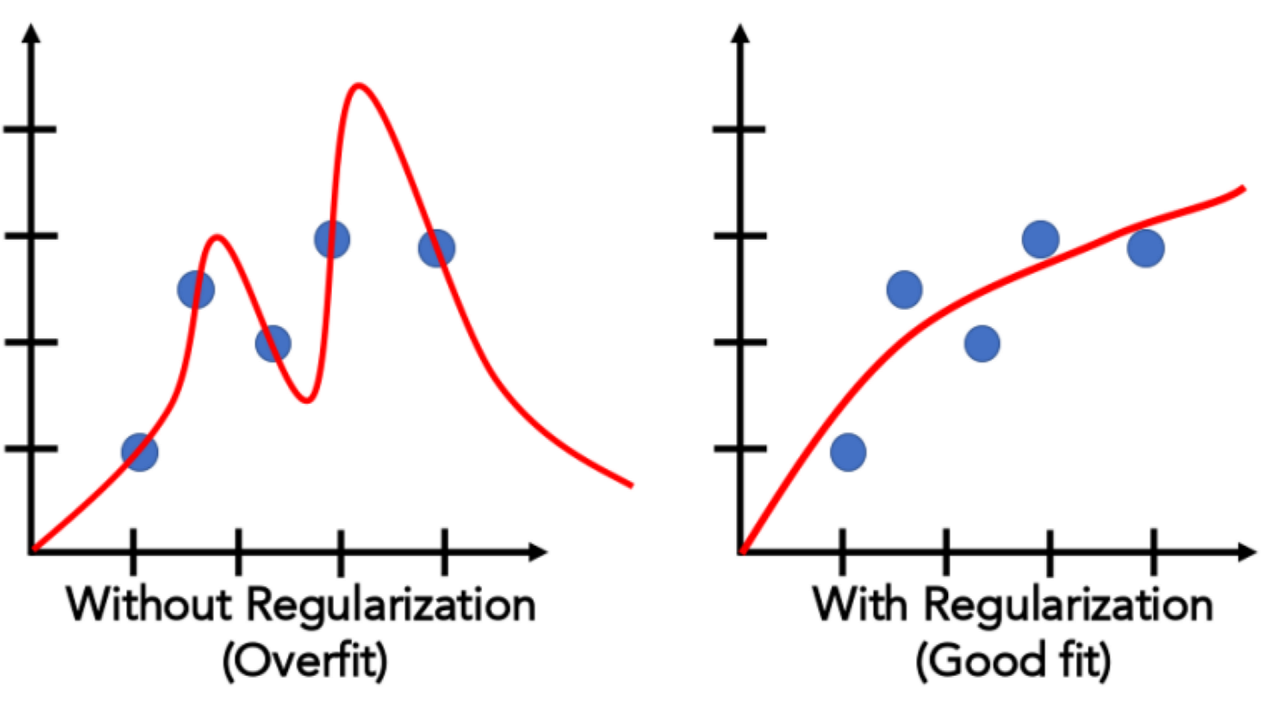

In [142]:
ridge_model = Ridge(alpha=1.0)

In [143]:
ridge_model.fit(X_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [144]:
ridge_predictions = ridge_model.predict(X_test)

In [145]:
ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_rmse = mean_squared_error(y_test, ridge_predictions) ** 0.5
ridge_r2 = r2_score(y_test, ridge_predictions)

print(f"Ridge Regression MAE:  {ridge_mae:.2f}")
print(f"Ridge Regression RMSE: {ridge_rmse:.2f}")
print(f"Ridge Regression R²:   {ridge_r2:.3f}")

Ridge Regression MAE:  320.85
Ridge Regression RMSE: 428.74
Ridge Regression R²:   0.566


### Train a Decision Tree model

A Decision Tree learns a sequence of rules.

It can capture non-linear relationships, but a deep tree can fit the training data too closely.

In [146]:
RANDOM_STATE = 42

In [147]:
tree_model = DecisionTreeRegressor(random_state=RANDOM_STATE)

In [148]:
tree_model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [149]:
tree_predictions = tree_model.predict(X_test)

In [150]:
tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = mean_squared_error(y_test, tree_predictions) ** 0.5
tree_r2 = r2_score(y_test, tree_predictions)

print(f"Decision Tree MAE:  {tree_mae:.2f}")
print(f"Decision Tree RMSE: {tree_rmse:.2f}")
print(f"Decision Tree R²:   {tree_r2:.3f}")

Decision Tree MAE:  150.11
Decision Tree RMSE: 272.95
Decision Tree R²:   0.824


### Train a Random Forest model

#### Random forecst estimator

* A Random Forest trains many decision trees and averages their predictions.

* Averaging usually makes the model more stable than a single tree.

#### What does it do actually? A simple visualisation

![Random forest estimator](https://www.researchgate.net/profile/Matthew-Reno-2/publication/326560291/figure/fig11/AS:651621029642243@1532369968679/Random-Forest-visualization.png)

[Source](https://www.researchgate.net/figure/Random-Forest-visualization_fig11_326560291)

In [151]:
forest_model = RandomForestRegressor(
    n_estimators=150,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

In [152]:
forest_model.fit(X_train, y_train)

,n_estimators,150
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [153]:
forest_predictions = forest_model.predict(X_test)

In [154]:
forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = mean_squared_error(y_test, forest_predictions) ** 0.5
forest_r2 = r2_score(y_test, forest_predictions)

print(f"Random Forest MAE:  {forest_mae:.2f}")
print(f"Random Forest RMSE: {forest_rmse:.2f}")
print(f"Random Forest R²:   {forest_r2:.3f}")

Random Forest MAE:  104.24
Random Forest RMSE: 174.23
Random Forest R²:   0.928


### Discuss
* Run the code above by changing the number of estimators in the decision tree?
* Guess how our evaluation metric changes with more estimators?
* How does these changes relate to underfitting and overfitting?

### Train a Gradient Boosting model

Gradient Boosting builds trees one after another.

Each new tree focuses on correcting errors made by the previous trees.


#### What actually does gradient boosting estimator do?

#### Gradient boosting estimator

![Gradient boosting estimator](https://media.geeksforgeeks.org/wp-content/uploads/20250903173429506712/des.webp)

[Source](https://www.geeksforgeeks.org/machine-learning/ml-gradient-boosting/)

In [155]:
boosting_model = GradientBoostingRegressor(random_state=RANDOM_STATE)

In [156]:
boosting_model.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [157]:
boosting_predictions = boosting_model.predict(X_test)

In [158]:
boosting_mae = mean_absolute_error(y_test, boosting_predictions)
boosting_rmse = mean_squared_error(y_test, boosting_predictions) ** 0.5
boosting_r2 = r2_score(y_test, boosting_predictions)

print(f"Gradient Boosting MAE:  {boosting_mae:.2f}")
print(f"Gradient Boosting RMSE: {boosting_rmse:.2f}")
print(f"Gradient Boosting R²:   {boosting_r2:.3f}")

Gradient Boosting MAE:  169.62
Gradient Boosting RMSE: 253.13
Gradient Boosting R²:   0.849


### Compare the first test results

In [ ]:
# Putting all the results together in a DataFrame for easy comparison

initial_results = pd.DataFrame([
    ["Mean baseline", baseline_mae, baseline_rmse, baseline_r2],
    ["Linear Regression", linear_mae, linear_rmse, linear_r2],
    ["Ridge Regression", ridge_mae, ridge_rmse, ridge_r2],
    ["Decision Tree", tree_mae, tree_rmse, tree_r2],
    ["Random Forest", forest_mae, forest_rmse, forest_r2],
    ["Gradient Boosting", boosting_mae, boosting_rmse, boosting_r2],
], columns=["model", "MAE", "RMSE", "R2"])

initial_results.sort_values("RMSE").round(3)

,model,MAE,RMSE,R2
4,Random Forest,104.236,174.228,0.928
5,Gradient Boosting,169.624,253.130,0.849
3,Decision Tree,150.114,272.946,0.824
1,Linear Regression,320.856,428.712,0.566
2,Ridge Regression,320.845,428.737,0.566
0,Mean baseline,523.461,651.115,-0.000


### What we have done so far 

#### Simple evaluation ★☆☆

* This first comparison helps us understand the models, but we should not select a final model from one split alone. We compare
    - Multiple models
    - Single Train/Test Split
    - Single Evaluation

#### Next step: stronger evaluation ★★★

* The next section uses cross-validation on the training data to produce a more reliable comparison.
    - introduced a version of cross validation more suited for hyperparameter tuning
    - a baseline model (non-machine learning) to provide a comparison against the ML models

### Group discussion: Why cross-validate every model?

### Purpose

Explore why we should cross-validate all candidate models rather than select a winner from one train/test split.

### Time

10 minutes

### Group size

3–5 learners

---

## Scenario

You have seen the result above

A colleague says:

> “Random Forest has the lowest RMSE. Let’s select it and only cross-validate that model.”

---

### Step 1: Initial decision — 3 minutes

Discuss:

1. Would you select Random Forest from this evidence?
2. How confident are you?
3. What could be misleading about this result?

Be ready to share one concern with the wider group.

---

### Step 2: Reveal a second split — 4 minutes

The models are tested using a different random split with the result below.

| Model             | Test RMSE |
| ----------------- | --------: |
| Linear Regression |       325 |
| Ridge Regression  |       375 |
| Decision Tree     |       287 |
| Random Forest     |       191 |
| Gradient Boosting |       187 |

Discuss:

1. Why has the model ranking changed?
2. Which models appear sensitive to the data split?
3. What risk would the team take by trusting only the first result?

### Step 3: Key question - 3 minutes

> Was Random Forest genuinely the best model, or did it receive a favourable test set?

---

### Set up cross-validation

Five-fold cross-validation repeats the training and validation process five times.

Each fold uses a different section of the training data for validation. This helps us assess both average performance and consistency.

In [160]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

In [161]:
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

### Cross-validate one model

Start with Linear Regression so that the structure of `cross_validate()` is clear.

In [162]:
linear_cv_scores = cross_validate(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
)

In [163]:
linear_cv_scores

{'fit_time': array([0.002352  , 0.00182128, 0.00227404, 0.00210834, 0.00160003]),
 'score_time': array([0.00163388, 0.00094295, 0.00106287, 0.00104094, 0.00090408]),
 'test_mae': array([-314.80463898, -321.97206224, -306.08778979, -314.44954654,
        -302.61899628]),
 'test_rmse': array([-420.64723282, -430.90161573, -405.98921398, -424.22353471,
        -409.96892685]),
 'test_r2': array([0.58103336, 0.56643041, 0.58510113, 0.56485341, 0.59077601])}

Scikit-learn returns MAE and RMSE as negative values because its scoring system assumes that larger values are better.

We reverse the sign before reporting the errors.

In [164]:
# make it a nice print out 

print(f"Mean CV MAE:  {-linear_cv_scores['test_mae'].mean():.2f}")
print(f"Mean CV RMSE: {-linear_cv_scores['test_rmse'].mean():.2f}")
print(f"Mean CV R²:   {linear_cv_scores['test_r2'].mean():.3f}")

Mean CV MAE:  311.99
Mean CV RMSE: 418.35
Mean CV R²:   0.578


### Cross-validate all candidate models

In [165]:
models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model,
    "Gradient Boosting": boosting_model,
}

In [166]:

cv_rows = []

# loop through each model and perform cross-validation

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )

    cv_rows.append({
        "model": model_name,
        "mean_MAE": -scores["test_mae"].mean(),
        "std_MAE": scores["test_mae"].std(),
        "mean_RMSE": -scores["test_rmse"].mean(),
        "std_RMSE": scores["test_rmse"].std(),
        "mean_R2": scores["test_r2"].mean(),
        "std_R2": scores["test_r2"].std(),
    })

In [167]:
cv_results = pd.DataFrame(cv_rows).sort_values("mean_RMSE")
cv_results.round(3)

,model,mean_MAE,std_MAE,mean_RMSE,std_RMSE,mean_R2,std_R2
3,Random Forest,111.961,2.604,187.106,6.960,0.916,0.004
4,Gradient Boosting,168.940,4.295,251.855,5.619,0.847,0.004
2,Decision Tree,151.139,7.239,262.731,16.118,0.833,0.017
1,Ridge Regression,311.941,6.843,418.343,9.141,0.578,0.010
0,Linear Regression,311.987,6.874,418.346,9.169,0.578,0.010


### Discuss 

1. Which model has the lowest mean RMSE?
2. Which model is most consistent across folds?
3. Are the differences large enough to matter?
4. Would you choose the most accurate model if it were much harder to explain?

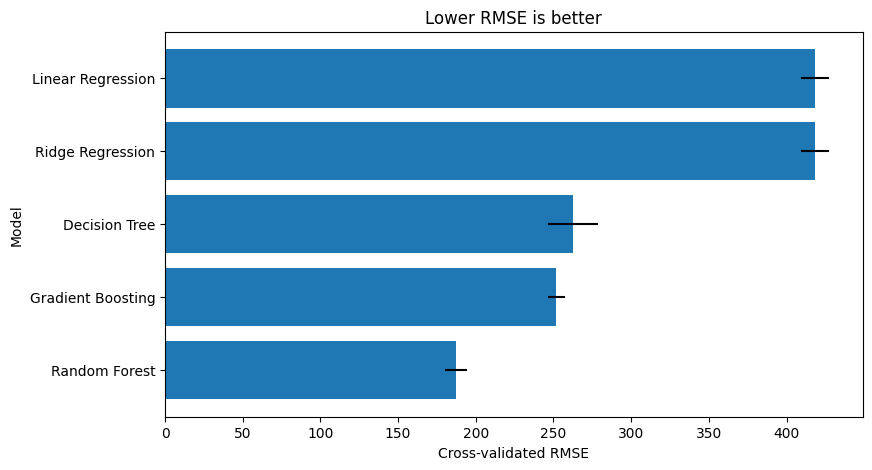

In [ ]:
# Let's visualise the cross-validated RMSE for each model, 
# We also include error bars representing the standard deviation of the RMSE across the folds.

plot_data = cv_results.sort_values("mean_RMSE", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(plot_data["model"], plot_data["mean_RMSE"], xerr=plot_data["std_RMSE"])
plt.xlabel("Cross-validated RMSE")
plt.ylabel("Model")
plt.title("Lower RMSE is better")
plt.show()


---

### Whole group challenge

---

#### Compare all models

The team now cross-validates every candidate using the same five folds.

Discuss:

1. Which model has the lowest average RMSE?
2. Which model is the most consistent?
3. Does the winner from the original split remain the strongest candidate?
4. Which model would you take forward for tuning, and why?

---

### Your conclusion

Prepare a 20-second explanation:

> We should cross-validate every candidate model because __________.
> Using the same folds makes the comparison fair because __________.
> We would take __________ forward because __________.

---

### Key takeaway

> Do not use cross-validation only to confirm a winner. Use cross-validation to help choose the winner.


## Hyperparameter tuning

A parameter is learned from the data. A hyperparameter is selected before training.

For a Random Forest:

- `n_estimators` controls the number of trees
- `max_depth` limits tree depth
- `min_samples_split` controls the minimum data required to split a node
- `max_features` controls how many features are considered at each split

In [169]:
# We will perform hyperparameter tuning for the Random Forest model using GridSearchCV.
# We manually define a parameter grid to search over. 
# This grid includes different values for the number of trees in the forest (`n_estimators`), the maximum depth of the trees (`max_depth`), the minimum number of samples required to split an internal node (`min_samples_split`), and the number of features to consider when looking for the best split (`max_features`).

parameter_grid = {
    "n_estimators": [10, 100],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", 1.0],
}

In [170]:
# Set up the Random Forest model for hyperparameter tuning. 
# We specify a random state for reproducibility and 
# Note: set `n_jobs=-1` to use all available CPU cores for parallel processing.

tuning_model = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

In [171]:

# Set up the GridSearchCV for hyperparameter tuning.
grid_search = GridSearchCV(
    estimator=tuning_model,
    param_grid=parameter_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    refit=True,
)

In [172]:
# Fit the grid search to the training data. 
# This will perform an exhaustive search over the specified parameter grid, using cross-validation to evaluate each combination of hyperparameters. The best combination of hyperparameters will be selected based on the scoring metric (in this case, negative root mean squared error).
grid_search.fit(X_train, y_train)

,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [None, 5, ...], 'max_features': ['sqrt', 1.0], 'min_samples_split': [2, 5], 'n_estimators': [10, 100]}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [173]:
print("Best parameters:")
print(grid_search.best_params_)
print(f"Best cross-validated RMSE: {-grid_search.best_score_:.2f}")

Best parameters:
{'max_depth': None, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 100}
Best cross-validated RMSE: 187.80


## Review the tuning results

In [174]:
tuning_results = pd.DataFrame(grid_search.cv_results_)

In [175]:
# sort the results by rank_test_score to see the best performing hyperparameter combinations at the top
tuning_results = tuning_results.sort_values("rank_test_score")  
tuning_results.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,param_max_features,param_min_samples_split,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
5,1.948647,0.105007,0.030045,0.002356,None,1.0,2,100,"{'max_depth': None, 'max_features': 1.0, 'min_...",-195.636293,-194.519162,-174.186342,-186.963144,-187.717192,-187.804427,7.649750,1
7,1.878234,0.105638,0.029257,0.001362,None,1.0,5,100,"{'max_depth': None, 'max_features': 1.0, 'min_...",-196.501047,-195.984245,-175.506679,-186.471256,-188.162900,-188.525225,7.656152,2
6,0.153527,0.060730,0.030369,0.012766,None,1.0,5,10,"{'max_depth': None, 'max_features': 1.0, 'min_...",-200.337038,-205.330785,-180.884835,-195.543571,-200.971001,-196.613446,8.454339,3
4,0.193392,0.081477,0.053424,0.042808,None,1.0,2,10,"{'max_depth': None, 'max_features': 1.0, 'min_...",-203.805117,-204.811361,-179.951055,-197.032113,-201.831571,-197.486243,9.166858,4
21,0.839081,0.323010,0.017650,0.005379,10,1.0,2,100,"{'max_depth': 10, 'max_features': 1.0, 'min_sa...",-223.298625,-229.079413,-200.191672,-216.155949,-217.743788,-217.293889,9.684406,5


In [176]:
# Perform a summary of the tuning results, focusing on the top 10 combinations of hyperparameters based on their rank in terms of test score. The summary includes the rank, mean and standard deviation of the test scores, and the specific hyperparameter values for each combination.

tuning_summary = (
    tuning_results[[
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "param_n_estimators",
        "param_max_depth",
        "param_min_samples_split",
        "param_max_features",
    ]]
    .assign(mean_CV_RMSE=lambda frame: -frame["mean_test_score"])
    .sort_values("rank_test_score")
    .drop(columns="mean_test_score")
    .head(10)
)

tuning_summary.round(3)

,rank_test_score,std_test_score,param_n_estimators,param_max_depth,param_min_samples_split,param_max_features,mean_CV_RMSE
5,1,7.650,100,None,2,1.0,187.804
7,2,7.656,100,None,5,1.0,188.525
6,3,8.454,10,None,5,1.0,196.613
4,4,9.167,10,None,2,1.0,197.486
21,5,9.684,100,10,2,1.0,217.294
23,6,9.868,100,10,5,1.0,217.303
1,7,8.940,100,None,2,sqrt,220.599
22,8,10.213,10,10,5,1.0,222.234
20,9,10.119,10,10,2,1.0,222.825
3,10,8.561,100,None,5,sqrt,225.324


## Evaluate the final model on the test set

The test set has not been used during cross-validation or tuning.

We now use it once to estimate how the selected model performs on unseen data.

In [177]:
final_model = grid_search.best_estimator_

In [178]:
final_predictions = final_model.predict(X_test)

In [179]:
final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = mean_squared_error(y_test, final_predictions) ** 0.5
final_r2 = r2_score(y_test, final_predictions)

print(f"Final MAE:  {final_mae:.2f}")
print(f"Final RMSE: {final_rmse:.2f}")
print(f"Final R²:   {final_r2:.3f}")

Final MAE:  104.04
Final RMSE: 173.58
Final R²:   0.929


In [180]:
final_comparison = pd.DataFrame([
    ["Mean baseline", baseline_mae, baseline_rmse, baseline_r2],
    ["Tuned Random Forest", final_mae, final_rmse, final_r2],
], columns=["model", "MAE", "RMSE", "R2"])

final_comparison.round(3)

,model,MAE,RMSE,R2
0,Mean baseline,523.461,651.115,-0.000
1,Tuned Random Forest,104.041,173.579,0.929


### Interpret the final metrics

A strong interpretation should mention all three measures:

- MAE describes the typical error in bike counts
- RMSE highlights the effect of larger mistakes
- $R^2$ shows improvement over predicting the mean

Do not describe $R^2$ as a percentage accuracy score.

## Plot actual and predicted values

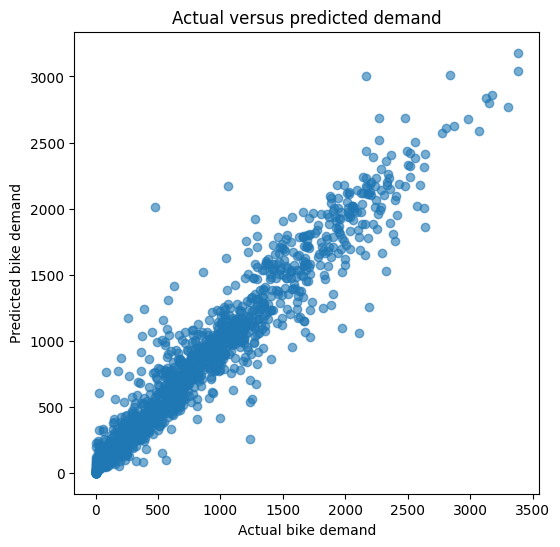

In [181]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, final_predictions, alpha=0.6)

plt.xlabel("Actual bike demand")
plt.ylabel("Predicted bike demand")
plt.title("Actual versus predicted demand")
plt.show()

## Examine residuals

A residual is:

```text
actual value - predicted value
```

- positive residual: the model under-predicted
- negative residual: the model over-predicted

In [184]:
# calculate the residuals
residuals = y_test.squeeze() - final_predictions

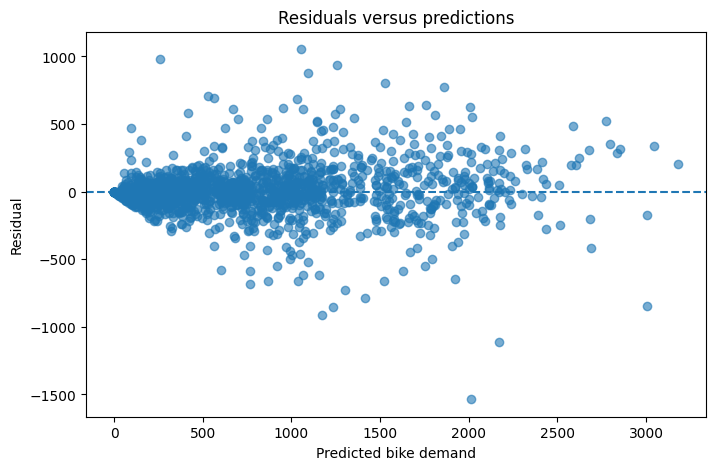

In [185]:
plt.figure(figsize=(8, 5))
plt.scatter(final_predictions, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted bike demand")
plt.ylabel("Residual")
plt.title("Residuals versus predictions")
plt.show()

## Inspect the largest errors

In [186]:
error_review = X_test.copy()
error_review["actual_demand"] = y_test
error_review["predicted_demand"] = final_predictions
error_review["residual"] = residuals
error_review["absolute_error"] = np.abs(residuals)

In [187]:
error_review.sort_values("absolute_error", ascending=False).head(10)

,hour,temperature_c,humidity_percent,wind_speed_ms,visibility_10m,solar_radiation_MJm2,temperature_dewpoint_gap_c,is_raining,is_snowing,seasons_Spring,...,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday,actual_demand,predicted_demand,residual,absolute_error
234,1.080477,0.785170,0.623054,0.747835,-0.276555,-0.499149,-0.600027,False,False,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,477,2012.00,-1535.00,1535.00
1321,1.080477,1.070550,-0.560779,0.071591,0.921309,-0.613466,0.633500,False,False,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1058,2172.57,-1114.57,1114.57
1237,-0.512758,-0.406714,1.313624,-0.508046,-1.088223,-0.361970,-1.198100,False,False,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2108,1054.67,1053.33,1053.33
900,-0.512758,-0.591372,1.560256,1.037654,0.626752,-0.293381,-1.347619,False,False,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1235,257.19,977.81,977.81
1207,0.501119,0.978221,-1.004717,0.361410,0.067094,1.455655,1.212883,False,False,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,2191,1256.61,934.39,934.39
603,1.225317,1.364324,0.179117,0.361410,0.842761,-0.659192,-0.132782,True,False,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,257,1172.39,-915.39,915.39
420,0.356280,0.936254,-0.807411,-0.508046,0.544931,1.547107,0.932536,False,False,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1970,1092.04,877.96,877.96
526,0.356280,0.650873,-1.300675,-0.218227,0.914764,0.129589,1.605369,False,False,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,384,1235.90,-851.90,851.90
277,0.935638,1.146092,-0.314147,0.747835,-0.112913,0.586853,0.353153,False,False,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2162,3004.61,-842.61,842.61
1009,-0.512758,0.667660,0.475075,-0.411440,0.921309,-0.453423,-0.487888,False,False,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,2329,1526.69,802.31,802.31


### Learner task

Review the ten largest errors.

1. Do the cases share any visible conditions?
2. Does the model mainly under-predict or over-predict them?
3. What additional information might improve these predictions?
4. What could be the operational impact of these mistakes?

## Check for overfitting

In [ ]:
# First , we will evaluate the model's performance on the training data to check for overfitting or underfitting.
train_predictions = final_model.predict(X_train)

In [ ]:
# Evaluate the model's performance on the training data to check for overfitting or underfitting.

generalisation_check = pd.DataFrame([
    [
        "Training",
        mean_absolute_error(y_train, train_predictions),
        mean_squared_error(y_train, train_predictions) ** 0.5,
        r2_score(y_train, train_predictions),
    ],
    [
        "Test",
        final_mae,
        final_rmse,
        final_r2,
    ],
], columns=["dataset", "MAE", "RMSE", "R2"])

generalisation_check.round(3)

,dataset,MAE,RMSE,R2
0,Training,40.164,68.662,0.989
1,Test,104.041,173.579,0.929


A large gap between training and test performance may suggest overfitting.

A small gap does not prove that the model will perform well in every future setting, but it is a useful diagnostic.

## Train a regression model with low-code approach

To do that, we are using a brilliant tool called **PyCaret**. We are completely skipping the dense mathematical jargon and focusing on the fun, practical part of data science.

### What exactly is PyCaret?

Think of PyCaret as the automatic gearbox of machine learning.

In traditional data science, building a model is a bit like building a car from scratch. You have to manually prepare the data, tune the engine, wire the dashboard, and write lines of intimidating code just to get the wheels turning.

PyCaret changes the game by handing you the keys to a pre-built, high-performance vehicle instead. It is a "low-code" library, which means it handles all the tedious, repetitive setup behind the scenes so you can focus entirely on solving the problem.

### Why PyCaret is our secret weapon today:

* **It is a master multi-tasker:** Instead of testing one machine learning model at a time, PyCaret lets us run a quick "speed-date" across dozens of different models simultaneously to instantly see which one handles our data best.
* **It saves your sanity:** Data preparation tasks that usually require thirty lines of complex code can be completed in just one or two clean lines with PyCaret.
* **It does the heavy lifting:** It automatically cleans up messy data, handles missing information, and gets everything ready for training without you having to micromanage the process.

> **Take a deep breath—you have got this.** If you can click the "Run" button on a code block, you can pilot PyCaret to build a machine learning model today.

---

In [192]:
# Read the raw data from the csv file
df_py = pd.read_csv("seoulbikerentals.csv")

In [196]:
# Create a workflow performed using pycaret

from pycaret.regression import RegressionExperiment

reg_exp = RegressionExperiment(target="rented_bike_count",
    session_id=123,
    fold=5,
    n_jobs=1,
    train_size=0.8).fit(df_py)



In [197]:
result = reg_exp.compare_models()

result.leaderboard

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,catboost,95.1889,23943.3722,154.5182,0.9421,0.9009,0.3839
1,et,103.0219,29877.4251,172.7456,0.9277,0.5321,0.3618
2,rf,113.0053,35356.2677,187.9882,0.9144,0.6379,0.4105
3,gbr,162.1981,58750.9156,242.3501,0.8578,0.9995,0.6872
4,dt,155.5467,77535.8897,278.2545,0.8122,0.5911,0.4136
5,ada,335.2356,156339.3639,394.9933,0.6219,1.4869,2.1829
6,kr,312.5956,177284.8575,420.9888,0.5708,1.3200,1.4300
7,lr,312.7293,177425.1113,421.1553,0.5705,1.3190,1.4308
8,ridge,312.7016,177423.5815,421.1531,0.5705,1.3207,1.4300
9,br,312.6689,177428.6754,421.1588,0.5704,1.3213,1.4288


#### Which one is our best model?

Ask yourself:

- Which model performed best?
- Which metric is PyCaret sorting by?
- Is that the right metric for this problem?
- What has this approach speeds up your workflow?

## Responsible interpretation

Before using the model operationally, consider:

- whether the training data represents future operating conditions
- whether any feature would be unavailable at prediction time
- whether travel patterns could change over time
- the impact of under-predicting demand
- who will review unusual forecasts
- how performance will be monitored

Model selection is a technical and business decision.

## Knowledge check

1. Why do we keep a separate test set?
2. Why is a baseline useful?
3. What is the difference between MAE and RMSE?
4. Why can $R^2$ be misleading on its own?
5. What does cross-validation add to a single train/test split?
6. What is the difference between a parameter and a hyperparameter?
7. Why must tuning use only the training data?
8. What evidence would you need before deploying this model?

## Key takeaways

- Begin with a baseline.
- Train different algorithms because they make different assumptions.
- Use MAE, RMSE and $R^2$ together.
- Use cross-validation to compare average performance and stability.
- Tune hyperparameters on the training data only.
- Use the test set once for final evaluation.
- Investigate individual errors as well as summary scores.
- Select a model using performance, stability, explainability and operational impact.

### Optional Stretch: using Pipeline

Above we wrote explicit loops to scale data and fit estimators.
`Pipeline` lets us chain transformers and estimators together and
integrate cleanly with tools like `GridSearchCV`.
Below are a few examples revisiting earlier sections using pipelines.

In [ ]:
# Use a pipeline to preprocess the data and train a model in one step. 
# This is particularly useful when you have a sequence of transformations that need to be applied to the data before fitting the model.

model_pipeline = Pipeline([
    ("scaler", StandardScaler()),  # Standardise features by removing the mean and scaling to unit variance
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=None,
        min_samples_split=2,
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])  

model_pipeline.fit(X_train, y_train)
model_pipeline_predictions = model_pipeline.predict(X_test)
model_pipeline_mae = mean_absolute_error(y_test, model_pipeline_predictions)
model_pipeline_rmse = mean_squared_error(y_test, model_pipeline_predictions) ** 0.5
model_pipeline_r2 = r2_score(y_test, model_pipeline_predictions)

print(f"Pipeline MAE:  {model_pipeline_mae:.2f}")
print(f"Pipeline RMSE: {model_pipeline_rmse:.2f}")
print(f"Pipeline R²:   {model_pipeline_r2:.3f}")


Pipeline MAE:  133.19
Pipeline RMSE: 208.43
Pipeline R²:   0.898


---

#### What should I learn next?

In the next workshop we will continue our study of classification model and evaluation metrics

### What packages does this chapter use?

Sklearn, numpy, pandas, pycaret

## Appendix

### Resources

- [Fighting Fraud with Machine Learning at Monzo](https://monzo.com/blog/2017/02/03/fighting-fraud-with-machine-learning): Is a credit card transaction fraudulent or not-fraudulent? Read how Monzo is fighting fraud with Machine Learning. (6 min read) 
- [Face Recognition](https://towardsdatascience.com/face-recognition-for-beginners-a7a9bd5eb5c2): For Beginners - A comprehensive overview of the techniques and methods behind face recognition.? (9 min read)
- [Handwritten Digit Recognition using Machine Learning](https://medium.com/@himanshubeniwal/handwritten-digit-recognition-using-machine-learning-ad30562a9b64): Read how classification and other machine learning techniques you are already familiar with (such as neural nets) are used in handwritten digit recognition. (17 min read)
- [A visual introduction to machine learning](http://www.r2d3.us/visual-intro-to-machine-learning-part-1/)
- [MLU explain: Logistic regression](https://mlu-explain.github.io/logistic-regression/)
- [StatQuest video on Logistic Regression (up to 5:15)](https://www.youtube.com/watch?v=yIYKR4sgzI8) (5min watch)
- [4 Logistic Regressions Examples to Help You Understand](https://magoosh.com/data-science/4-logistic-regressions-examples/) (2min read)
- [StatQuest video on Logistic Regression (from 6:10 to 8:08)](https://www.youtube.com/watch?v=yIYKR4sgzI8) (2 min)

---